In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

In [ ]:
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

# Load Fashion-MNIST
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# Use a subset for faster laboratory training
x_train = x_train[:10000]

# Resize to 32x32 and convert grayscale images to RGB
images = tf.convert_to_tensor(x_train[..., np.newaxis], dtype=tf.float32)
images = tf.image.resize(images, (32, 32))
images = tf.repeat(images, repeats=3, axis=-1)

# Normalize pixel values to [-1, 1]
images = images / 127.5 - 1.0

train_ds = (
    tf.data.Dataset.from_tensor_slices(images)
    .shuffle(10000)
    .batch(64, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset shape:", images.shape)

TensorFlow version: 2.21.0
GPU available: False
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (10000, 32, 32, 3)


In [ ]:
LATENT_DIM = 128
STYLE_DIM = 128

def build_mapping_network():
    z = layers.Input(shape=(LATENT_DIM,))
    x = z

    for _ in range(8):
        x = layers.Dense(STYLE_DIM)(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)

    return tf.keras.Model(z, x, name="mapping_network")

mapping_network = build_mapping_network()
mapping_network.summary()

Model: "mapping_network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 128)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,096 (516.00 KB)

 Trainable params: 132,096 (516.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class AdaIN(layers.Layer):
    def __init__(self, channels):
        super().__init__()
        self.channels = channels
        self.style_dense = layers.Dense(2 * channels)

    def call(self, inputs):
        x, w = inputs

        style = self.style_dense(w)
        gamma, beta = tf.split(style, 2, axis=-1)

        mean, variance = tf.nn.moments(
            x, axes=[1, 2], keepdims=True
        )

        x = (x - mean) / tf.sqrt(variance + 1e-8)

        gamma = gamma[:, None, None, :]
        beta = beta[:, None, None, :]

        return (1.0 + gamma) * x + beta

In [ ]:
class StyleBlock(layers.Layer):
    def __init__(self, channels):
        super().__init__()
        self.up = layers.UpSampling2D(interpolation="nearest")
        self.conv = layers.Conv2D(
            channels, 3, padding="same"
        )
        self.adain = AdaIN(channels)
        self.activation = layers.LeakyReLU(negative_slope=0.2)

    def call(self, inputs):
        x, w = inputs
        x = self.up(x)
        x = self.conv(x)
        x = self.adain([x, w])
        return self.activation(x)


class StyleGenerator(tf.keras.Model):
    def __init__(self):
        super().__init__()

        self.constant = self.add_weight(
            name="learned_constant",
            shape=(1, 4, 4, 128),
            initializer="random_normal",
            trainable=True
        )

        self.initial_conv = layers.Conv2D(
            128, 3, padding="same"
        )
        self.initial_adain = AdaIN(128)
        self.initial_activation = layers.LeakyReLU(
            negative_slope=0.2
        )

        self.blocks = [
            StyleBlock(128),  # 8x8
            StyleBlock(64),   # 16x16
            StyleBlock(32)    # 32x32
        ]

        self.to_rgb = layers.Conv2D(
            3, 1, padding="same", activation="tanh"
        )

    def call(self, inputs, training=False):
        z, w2, cut = inputs

        w1 = mapping_network(z)

        batch_size = tf.shape(z)[0]
        x = tf.tile(self.constant, [batch_size, 1, 1, 1])

        # Initial synthesis layer
        x = self.initial_conv(x)
        x = self.initial_adain([x, w1])
        x = self.initial_activation(x)

        # Optional style mixing:
        # early blocks use w1; later blocks use w2
        for i, block in enumerate(self.blocks):
            if w2 is not None:
                style = tf.cond(
                    tf.cast(i, tf.int32) < cut,
                    lambda: w1,
                    lambda: w2
                )
            else:
                style = w1

            x = block([x, style])

        return self.to_rgb(x)


generator = StyleGenerator()

In [ ]:
def build_discriminator():
    image = layers.Input(shape=(32, 32, 3))
    x = image

    for filters in [32, 64, 128]:
        x = layers.Conv2D(
            filters, 4, strides=2, padding="same"
        )(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    score = layers.Dense(1)(x)

    return tf.keras.Model(
        image, score, name="discriminator"
    )

discriminator = build_discriminator()

print("Generator and discriminator created successfully.")

Generator and discriminator created successfully.


In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.0, beta_2=0.99
)
d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.0, beta_2=0.99
)

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    z = tf.random.normal((batch_size, LATENT_DIM))
    dummy_w2 = tf.zeros((batch_size, STYLE_DIM))

    with tf.GradientTape() as d_tape:
        fake_images = generator(
            (z, None, tf.constant(1)), training=True
        )

        real_scores = discriminator(real_images, training=True)
        fake_scores = discriminator(
            tf.stop_gradient(fake_images), training=True
        )

        d_loss = (
            cross_entropy(tf.ones_like(real_scores), real_scores)
            + cross_entropy(tf.zeros_like(fake_scores), fake_scores)
        )

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    z = tf.random.normal((batch_size, LATENT_DIM))

    with tf.GradientTape() as g_tape:
        fake_images = generator(
            (z, None, tf.constant(1)), training=True
        )
        fake_scores = discriminator(fake_images, training=True)

        g_loss = cross_entropy(
            tf.ones_like(fake_scores), fake_scores
        )

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return d_loss, g_loss


EPOCHS = 5

for epoch in range(EPOCHS):
    d_losses = []
    g_losses = []

    for real_batch in train_ds:
        d_loss, g_loss = train_step(real_batch)
        d_losses.append(float(d_loss))
        g_losses.append(float(g_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"D Loss: {np.mean(d_losses):.4f} | "
        f"G Loss: {np.mean(g_losses):.4f}"
    )

Epoch 1/5 | D Loss: 1.1844 | G Loss: 0.9238
Epoch 2/5 | D Loss: 0.9009 | G Loss: 1.4445
Epoch 3/5 | D Loss: 0.8527 | G Loss: 1.6319
Epoch 4/5 | D Loss: 0.8710 | G Loss: 1.6659
Epoch 5/5 | D Loss: 0.8360 | G Loss: 1.7169


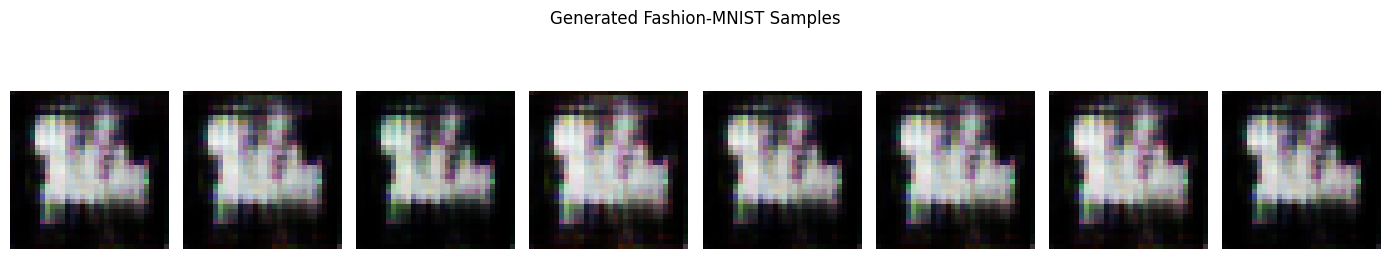

In [ ]:

def show_images(generated, title, n=8):
    generated = (generated.numpy() + 1.0) / 2.0
    generated = np.clip(generated, 0, 1)

    plt.figure(figsize=(14, 3))
    for i in range(min(n, len(generated))):
        plt.subplot(1, n, i + 1)
        plt.imshow(generated[i])
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


z = tf.random.normal((8, LATENT_DIM))
samples = generator(
    (z, None, tf.constant(1)), training=False
)

show_images(samples, "Generated Fashion-MNIST Samples")


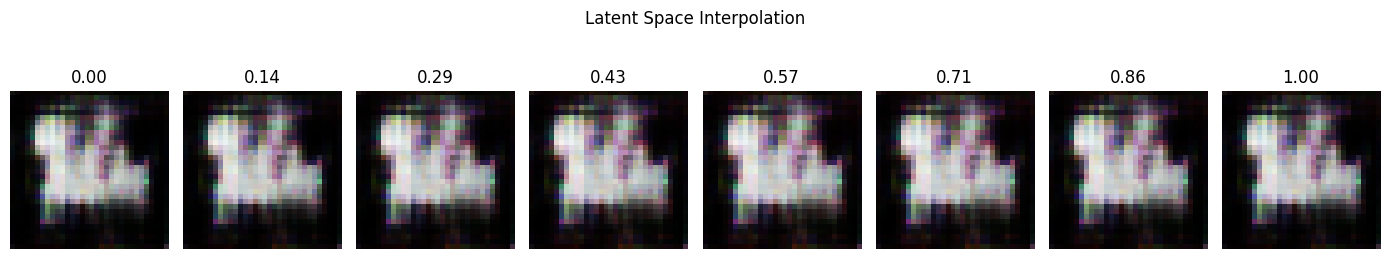

In [ ]:
z1 = tf.random.normal((1, LATENT_DIM))
z2 = tf.random.normal((1, LATENT_DIM))

steps = np.linspace(0, 1, 8)
interpolated_images = []

for t in steps:
    z_interp = (1 - t) * z1 + t * z2

    generated = generator(
        (z_interp, None, tf.constant(1)), training=False
    )
    interpolated_images.append(generated[0].numpy())

plt.figure(figsize=(14, 3))

for i, image in enumerate(interpolated_images):
    image = (image + 1.0) / 2.0
    plt.subplot(1, len(steps), i + 1)
    plt.imshow(np.clip(image, 0, 1))
    plt.title(f"{steps[i]:.2f}")
    plt.axis("off")

plt.suptitle("Latent Space Interpolation")
plt.tight_layout()
plt.savefig("exp9_latent_interpolation.png", dpi=150)
plt.show()
